<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris=load_iris()
x=iris.data

pd.DataFrame(x, columns=iris.feature_names).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

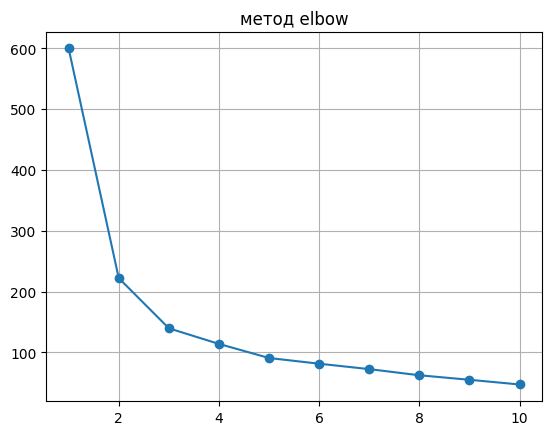

In [5]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

x_iris=pd.DataFrame(x_scaled, columns=iris.feature_names)

wcss=[]
for i in range(1, 11):
  kmeans=KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
  kmeans.fit(x_iris)
  wcss.append(kmeans.inertia_)

plt.plot(range(1,11), wcss, marker='o')
plt.grid(True)
plt.title('метод elbow')
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

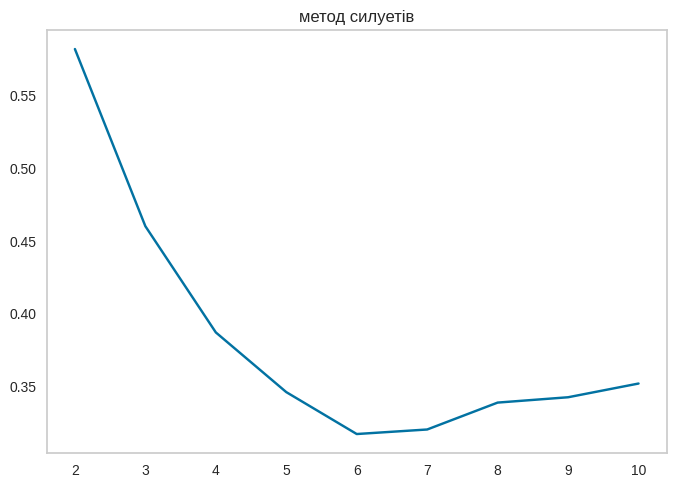

In [42]:
silhouette_scores=[]
for i in range(2,11):
  kmeans=KMeans(n_clusters=i, init='k-means++',max_iter=300, n_init=10, random_state=42)
  cluster_labels=kmeans.fit_predict(x_iris)
  silhouette_avg=silhouette_score(x_iris, cluster_labels)
  silhouette_scores.append(silhouette_avg)

plt.plot(range(2,11),silhouette_scores)
plt.title('метод силуетів')
plt.grid()
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

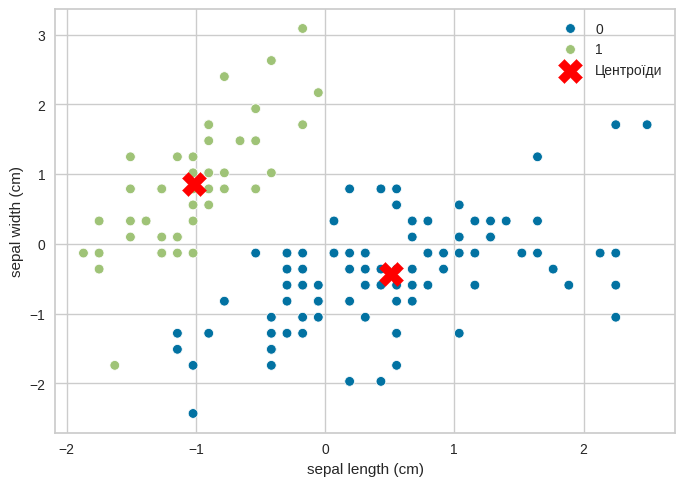

In [44]:
kmeans = KMeans(n_clusters=2, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters = kmeans.fit_predict(x_iris)

sns.scatterplot(x=x_iris.iloc[:, 0], y=x_iris.iloc[:, 1], hue=clusters, legend='full')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=300, c='red', marker='X', label='Центроїди')
plt.xlabel(x_iris.columns[0])
plt.ylabel(x_iris.columns[1])
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [9]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [10]:
df=pd.read_csv(os.path.join(path, 'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [11]:
df.columns

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [13]:
df.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [14]:
df.duplicated().sum()

np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [15]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [16]:
x=df.drop(columns=['GradeClass', 'StudentID'])
y=df['GradeClass']

x_train, x_test, y_train, y_test=train_test_split(x,y, test_size=0.2, random_state=42, stratify=y)

scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [25]:
param_grid_rf={
    'C': [0.1, 1, 10, 100],
    'gamma':[1, 0.1,0.01,0.001],
    'kernel': ['rbf', 'linear']
}

svm=SVC(random_state=42)

grid_search_rf=GridSearchCV(estimator=svm, param_grid=param_grid_rf, cv=5, n_jobs=1, verbose=2)
grid_search_rf.fit(x_train,y_train)

print(grid_search_rf)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   1.2s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.6s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.4s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.5s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.5s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.1s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.2s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.1s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.2s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.2s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.3s
[CV] END .......................C=0.1, gamma=0.

### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report


param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100]
}

lr = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)

grid_search_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid_lr,
    cv=5,
    n_jobs=-1,
    verbose=2
)


grid_search_lr.fit(x_train, y_train)


print("Найкращі параметри:", grid_search_lr.best_params_)
print("Найкраща точність Cv:", grid_search_lr.best_score_)

best_lr = grid_search_lr.best_estimator_
y_pred_lr = best_lr.predict(x_test)

print("Точність на тесті:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Найкращі параметри: {'C': 100}
Найкраща точність Cv: 0.7976952414801854
Точність на тесті: 0.791231732776618
              precision    recall  f1-score   support

         0.0       0.31      0.19      0.24        21
         1.0       0.62      0.46      0.53        54
         2.0       0.61      0.77      0.68        78
         3.0       0.80      0.66      0.72        83
         4.0       0.91      0.97      0.94       243

    accuracy                           0.79       479
   macro avg       0.65      0.61      0.62       479
weighted avg       0.78      0.79      0.78       479



### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [27]:

param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'linear']
}


svm = SVC(random_state=42)


grid_search_svm = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    cv=5,
    n_jobs=-1,
    verbose=2
)


grid_search_svm.fit(x_train, y_train)


print("Найкращі параметри:", grid_search_svm.best_params_)
print("CV точність:", grid_search_svm.best_score_)


best_svm = grid_search_svm.best_estimator_
y_pred_svm=best_svm.predict(x_test)

print("Аccuracy:", accuracy_score(y_test, y_pred_svm))

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Найкращі параметри: {'C': 100, 'gamma': 1, 'kernel': 'linear'}
CV точність: 0.854677183437453
Аccuracy: 0.8496868475991649


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [28]:
models = {
    'Logistic Regression': grid_search_lr,
    'SVM': grid_search_svm,
    'Random Forest': grid_search_rf
}

results = []
for name, grid in models.items():
    cv_score = grid.best_score_
    test_acc = accuracy_score(y_test, grid.predict(x_test))
    results.append({'Модель': name, 'CV-точність': cv_score, 'Тестова accuracy': test_acc})

results_df = pd.DataFrame(results).sort_values('CV-точність', ascending=False)
print(results_df.to_string(index=False))


best_name = results_df.iloc[0]['Модель']
best_model = models[best_name]
print("\nОбрана модель:", best_name)
print("Найкращі параметри:", best_model.best_params_)

y_pred_best = best_model.predict(x_test)
print(classification_report(y_test, y_pred_best))

             Модель  CV-точність  Тестова accuracy
                SVM     0.854677          0.849687
      Random Forest     0.854677          0.849687
Logistic Regression     0.797695          0.791232

Обрана модель: SVM
Найкращі параметри: {'C': 100, 'gamma': 1, 'kernel': 'linear'}
              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00        21
         1.0       0.68      0.76      0.72        54
         2.0       0.76      0.87      0.81        78
         3.0       0.80      0.80      0.80        83
         4.0       0.94      0.95      0.95       243

    accuracy                           0.85       479
   macro avg       0.64      0.68      0.65       479
weighted avg       0.82      0.85      0.83       479



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

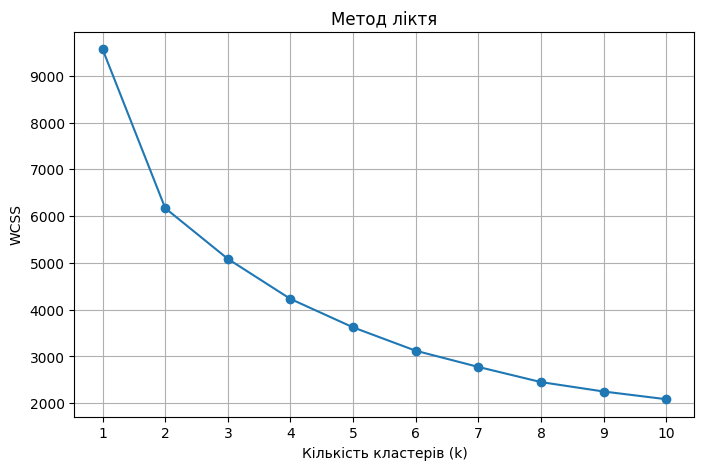

In [29]:

features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
x_cluster = df[features]

scaler_cluster = StandardScaler()
x_cluster_scaled = scaler_cluster.fit_transform(x_cluster)

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(x_cluster_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Метод ліктя')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

k = 2: silhouette = 0.3080
k = 3: silhouette = 0.2702
k = 4: silhouette = 0.2580
k = 5: silhouette = 0.2645
k = 6: silhouette = 0.2689
k = 7: silhouette = 0.2692
k = 8: silhouette = 0.2712
k = 9: silhouette = 0.2732
k = 10: silhouette = 0.2725


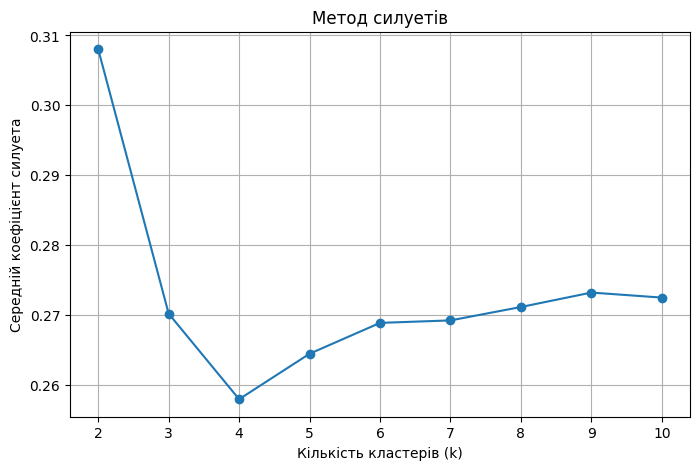

Найкраще k за силуетом: 2


In [30]:
sil_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(x_cluster_scaled)
    score = silhouette_score(x_cluster_scaled, labels)
    sil_scores.append(score)
    print(f"k = {k}: silhouette = {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), sil_scores, marker='o')
plt.title('Метод силуетів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

best_k = range(2, 11)[sil_scores.index(max(sil_scores))]
print("Найкраще k за силуетом:", best_k)

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [31]:
!pip install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [32]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [33]:
x_pca = df.drop(columns=['StudentID', 'GradeClass'])

print("Форма даних:", x_pca.shape)
print("Ознаки:", list(x_pca.columns))

Форма даних: (2392, 13)
Ознаки: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [34]:
scaler_pca = StandardScaler()
x_pca_scaled = scaler_pca.fit_transform(x_pca)

pca = PCA(random_state=42)
pca.fit(x_pca_scaled)

explained_var = pca.explained_variance_ratio_

for i, var in enumerate(explained_var, start=1):
    print(f"PC{i}: {var:.4f} ({var * 100:.2f}%)")

print("\nСума:", np.sum(explained_var))

PC1: 0.1525 (15.25%)
PC2: 0.0861 (8.61%)
PC3: 0.0827 (8.27%)
PC4: 0.0807 (8.07%)
PC5: 0.0786 (7.86%)
PC6: 0.0779 (7.79%)
PC7: 0.0763 (7.63%)
PC8: 0.0760 (7.60%)
PC9: 0.0744 (7.44%)
PC10: 0.0738 (7.38%)
PC11: 0.0717 (7.17%)
PC12: 0.0675 (6.75%)
PC13: 0.0018 (0.18%)

Сума: 0.9999999999999999


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Лікоть знайдено на компоненті: 2


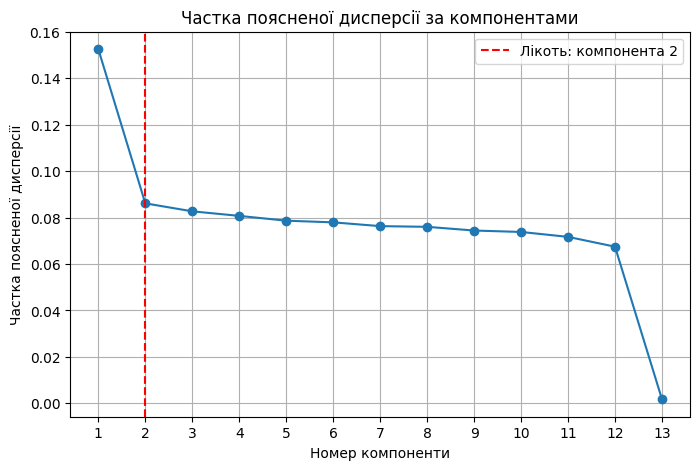

In [35]:
components = range(1, len(explained_var) + 1)

knee = KneeLocator(
    x=list(components),
    y=explained_var,
    curve='convex',
    direction='decreasing'
)

n_components = knee.knee
print("Лікоть знайдено на компоненті:", n_components)

plt.figure(figsize=(8, 5))
plt.plot(components, explained_var, marker='o')

if n_components is not None:
    plt.axvline(x=n_components, color='red', linestyle='--',
                label=f'Лікоть: компонента {n_components}')

plt.title('Частка поясненої дисперсії за компонентами')
plt.xlabel('Номер компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Кількість компонент: 2
Кумулятивна частка дисперсії: 0.2386


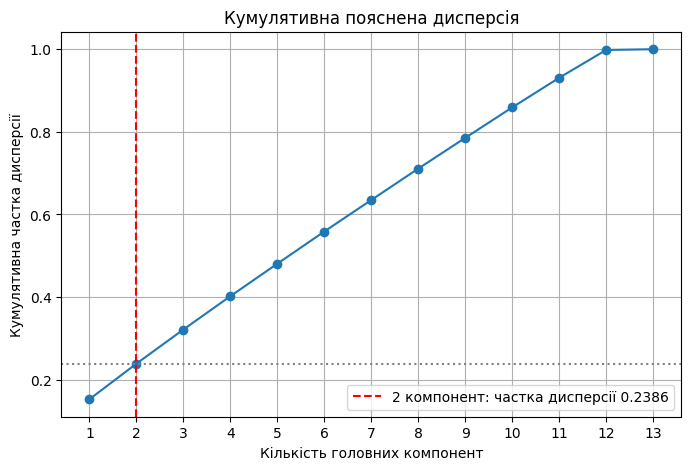

Форма даних до PCA:    (2392, 13)
Форма даних після PCA: (2392, 2)
Дисперсія після PCA:   0.23858271308863227


In [37]:
c_var = np.cumsum(explained_var)

components = range(1, len(c_var) + 1)

if n_components is None:
    raise ValueError("Не знайшов лікоть")

actual_var = c_var[n_components - 1]
print(f"Кількість компонент: {n_components}")
print(f"Кумулятивна частка дисперсії: {actual_var:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(components, c_var, marker='o')

plt.axvline(x=n_components, color='red', linestyle='--',
            label=f'{n_components} компонент: частка дисперсії {actual_var:.4f}')
plt.axhline(y=actual_var, color='gray', linestyle=':')

plt.title('Кумулятивна пояснена дисперсія')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

pca_final = PCA(n_components=n_components, random_state=42)
x_pca_reduced = pca_final.fit_transform(x_pca_scaled)

print("Форма даних до PCA:   ", x_pca_scaled.shape)
print("Форма даних після PCA:", x_pca_reduced.shape)
print("Дисперсія після PCA:  ", pca_final.explained_variance_ratio_.sum())

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [38]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

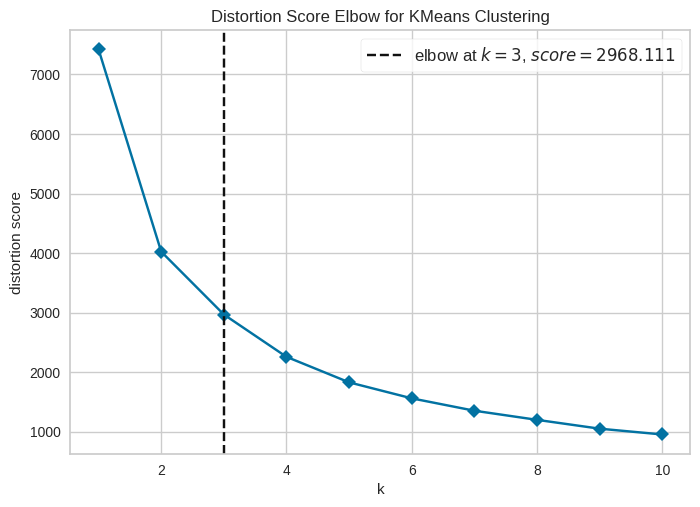

Оптимальна кількість кластерів (лікоть): 3


In [41]:
kmeans = KMeans(init='k-means++', n_init=10, random_state=42)

visualizer = KElbowVisualizer(kmeans, k=(1, 11), metric='distortion', timings=False)

visualizer.fit(x_pca_reduced)
visualizer.show()

optimal_k = visualizer.elbow_value_
print("Оптимальна кількість кластерів (лікоть):", optimal_k)

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

для pca взято 13 ознак, а kneelocator обрав 2 голоні компонети. Ознаки здебільшого слабо корельовані й дані майже не стискаються без втрат(для 90 відсотків треба буде мати майже всі компоненти). Кластеризація працює без ціьової змінної і шукає природні групи за схожістю ознак, тому кластери не зобов'язані збігатися з оцінками